In [20]:
# plots lightning climatology in PNW
import xarray as xr
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [21]:
# Generate sorted list of all files
filepaths = sorted([f"nc_ltgday_conus/ltgday_{i:03d}.nc" for i in range(1, 366)])  # or use glob.glob("ltgday_*.nc")

# Create time coordinate (e.g., for a non-leap year like 2021)
time_coord = pd.date_range("2021-01-01", periods=len(filepaths), freq="D")

# Open and expand each dataset with a new time dimension
def open_and_add_time(fp, time_val):
    ds = xr.open_dataset(fp)
    return ds.expand_dims(time=[time_val])  # "time" is now a new dimension with 1 value

# Load all datasets and stack them
datasets = [open_and_add_time(fp, t) for fp, t in zip(filepaths, time_coord)]
ds = xr.concat(datasets, dim="time")

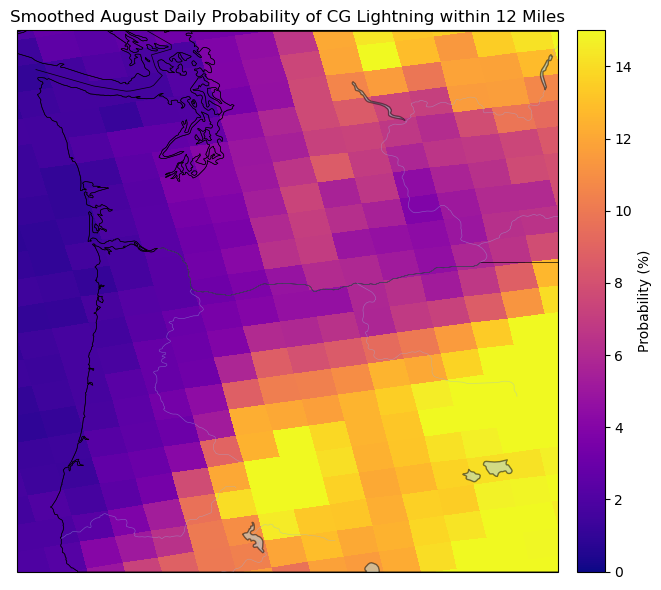

In [43]:
start_date = "2021-08-01"
end_date = "2021-08-31"

mean_data = ds.sel(time=slice(start_date, end_date))["climo_any"].mean(dim="time")
lat = ds["lat"].isel(time=0)
lon = ds["lon"].isel(time=0)

# Set up the map
fig = plt.figure(figsize=(10, 6))
ax = plt.axes(projection=ccrs.PlateCarree())
extent = [-125, -118, 42, 49]
ax.set_extent(extent)

# Add geographic features
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
ax.add_feature(cfeature.STATES, linewidth=0.3)
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax.add_feature(cfeature.RIVERS, linewidth=0.4, alpha=0.5)
ax.add_feature(cfeature.LAKES, facecolor='lightblue', edgecolor='black', alpha=0.5)

# Optional: Add ocean background (Cartopy doesn’t render ocean by default)
ax.stock_img()  # gives a light blue ocean and land background
# OR, instead:
# ax.add_feature(cfeature.OCEAN, facecolor='lightblue')  # simpler but flat

# Choose a good colormap (e.g., `plasma`) and make NaNs transparent
cmap = plt.cm.plasma
cmap.set_bad(color='none')  # transparent for NaN

# Plot data
mesh = ax.pcolormesh(
    lon, lat, mean_data,
    cmap=cmap,
    shading="auto",
    transform=ccrs.PlateCarree(),
    vmin=0, vmax=15  # Set range for colorbar
)

# Optional: Add transparency to lower values (via normalization)
# norm = mcolors.Normalize(vmin=0, vmax=mean_data.max())
# mesh.set_norm(norm)
# mesh.set_alpha(0.8)  # uniform transparency

# Colorbar
cbar = plt.colorbar(mesh, ax=ax, orientation="vertical", pad=0.02, label="Probability (%)")

# Title
plt.title(f"Smoothed August Daily Probability of CG Lightning within 12 Miles")
plt.tight_layout()
plt.savefig("august_lightning_climatology.png")
plt.show()

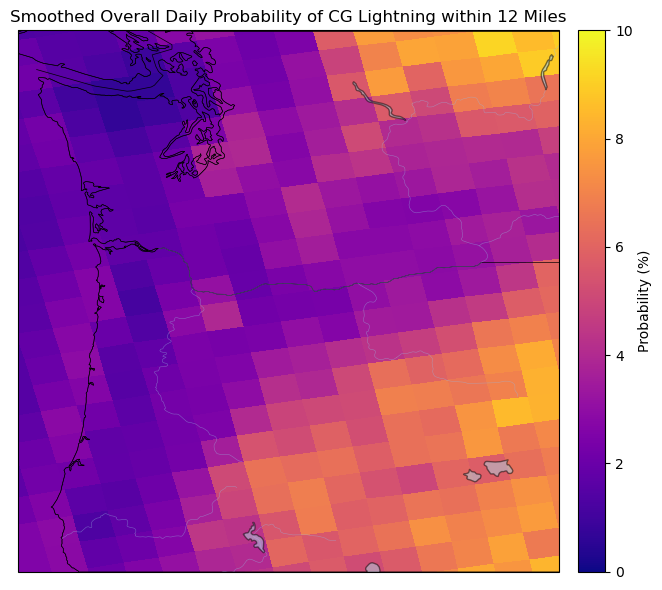

In [44]:
start_date = "2021-01-01"
end_date = "2021-12-31"

mean_data = ds.sel(time=slice(start_date, end_date))["climo_any"].mean(dim="time")
lat = ds["lat"].isel(time=0)
lon = ds["lon"].isel(time=0)

# Set up the map
fig = plt.figure(figsize=(10, 6))
ax = plt.axes(projection=ccrs.PlateCarree())
extent = [-125, -118, 42, 49]
ax.set_extent(extent)

# Add geographic features
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
ax.add_feature(cfeature.STATES, linewidth=0.3)
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax.add_feature(cfeature.RIVERS, linewidth=0.4, alpha=0.5)
ax.add_feature(cfeature.LAKES, facecolor='lightblue', edgecolor='black', alpha=0.5)

# Optional: Add ocean background (Cartopy doesn’t render ocean by default)
ax.stock_img()  # gives a light blue ocean and land background
# OR, instead:
# ax.add_feature(cfeature.OCEAN, facecolor='lightblue')  # simpler but flat

# Choose a good colormap (e.g., `plasma`) and make NaNs transparent
cmap = plt.cm.plasma
cmap.set_bad(color='none')  # transparent for NaN

# Plot data
mesh = ax.pcolormesh(
    lon, lat, mean_data,
    cmap=cmap,
    shading="auto",
    transform=ccrs.PlateCarree(),
    vmin=0, vmax=10  # Set range for colorbar
)

# Optional: Add transparency to lower values (via normalization)
# norm = mcolors.Normalize(vmin=0, vmax=mean_data.max())
# mesh.set_norm(norm)
# mesh.set_alpha(0.8)  # uniform transparency

# Colorbar
cbar = plt.colorbar(mesh, ax=ax, orientation="vertical", pad=0.02, label="Probability (%)")

# Title
plt.title(f"Smoothed Overall Daily Probability of CG Lightning within 12 Miles")
plt.tight_layout()
plt.savefig("lightning_climatology.png")
plt.show()